# 02 · Feature engineering
Builds the two ML datasets from `data/silver/events`:

1. **Session features** (`data/gold/session_features`) → anomaly / fraud detection (K-Means with and without Spark).
2. **User–product interactions** (`data/gold/als_train`, `als_test`) → implicit-feedback recommender (ALS with and without Spark).

Feeds report §4.3 (ML datasets) and §5.2 (Feature engineering). Metrics go to `ml/outputs/02_metrics.json`.

In [1]:
import os, json, time
from pyspark.sql import SparkSession, functions as F, Window

DATA = "/home/jovyan/work/data"
SILVER = f"{DATA}/silver/events"
GOLD = f"{DATA}/gold"
OUT = "/home/jovyan/work/ml/outputs"
FIG = "/home/jovyan/work/laporan/gambar"
os.makedirs(FIG, exist_ok=True)

spark = (SparkSession.builder.master("local[*]").appName("02_features")
         .config("spark.driver.memory", "12g")
         .config("spark.sql.shuffle.partitions", "64")
         .config("spark.sql.session.timeZone", "UTC")
         .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
events = spark.read.parquet(SILVER)
events.printSchema()

root
 |-- event_time: timestamp (nullable = true)
 |-- event_type: string (nullable = true)
 |-- product_id: long (nullable = true)
 |-- category_id: long (nullable = true)
 |-- category_code: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- price: double (nullable = true)
 |-- user_id: long (nullable = true)
 |-- user_session: string (nullable = true)
 |-- cat_l1: string (nullable = true)
 |-- cat_l2: string (nullable = true)
 |-- cat_l3: string (nullable = true)
 |-- event_date: date (nullable = true)



## 1. Session-level features
One row per `user_session`. The Assignment 1 design named these signals: event count, session duration and purchase-to-view ratio. The rest capture the behaviours the fraud rules look at (bots, scalpers, purchase without browsing).

In [2]:
t0 = time.time()
is_ = lambda t: (F.col("event_type") == t).cast("int")

sess = (events.groupBy("user_session")
    .agg(
        F.first("user_id").alias("user_id"),
        F.count("*").alias("n_events"),
        F.sum(is_("view")).alias("n_view"),
        F.sum(is_("cart")).alias("n_cart"),
        F.sum(is_("purchase")).alias("n_purchase"),
        F.countDistinct("product_id").alias("n_products"),
        F.countDistinct("category_id").alias("n_categories"),
        F.countDistinct("brand").alias("n_brands"),
        F.min("event_time").alias("t_first"),
        F.max("event_time").alias("t_last"),
        F.avg("price").alias("avg_price"),
        F.max("price").alias("max_price"),
        F.sum(F.when(F.col("event_type") == "purchase", F.col("price")).otherwise(0.0)).alias("purchase_value"),
    ))

sess = (sess
    .withColumn("duration_sec", F.col("t_last").cast("long") - F.col("t_first").cast("long"))
    .withColumn("events_per_min", F.col("n_events") / (F.greatest(F.col("duration_sec"), F.lit(1)) / 60.0))
    .withColumn("avg_gap_sec", F.col("duration_sec") / F.greatest(F.col("n_events") - 1, F.lit(1)))
    .withColumn("cart_per_view", F.col("n_cart") / F.greatest(F.col("n_view"), F.lit(1)))
    .withColumn("purchase_per_view", F.col("n_purchase") / F.greatest(F.col("n_view"), F.lit(1)))
    .withColumn("purchase_per_cart", F.col("n_purchase") / F.greatest(F.col("n_cart"), F.lit(1)))
    .withColumn("products_per_event", F.col("n_products") / F.col("n_events"))
    .withColumn("purchase_no_view", ((F.col("n_purchase") > 0) & (F.col("n_view") == 0)).cast("int"))
    .withColumn("hour", F.hour("t_first"))
    .withColumn("is_weekend", F.dayofweek("t_first").isin(1, 7).cast("int"))
    .drop("t_first", "t_last"))

sess.write.mode("overwrite").parquet(f"{GOLD}/session_features")
t_sess = time.time() - t0
sf = spark.read.parquet(f"{GOLD}/session_features")
n_sess = sf.count()
print(f"{n_sess:,} sessions in {t_sess/60:.1f} min")

22,995,676 sessions in 3.3 min


In [3]:
FEATS = ["n_events","n_view","n_cart","n_purchase","n_products","n_categories","n_brands",
         "duration_sec","events_per_min","avg_gap_sec","cart_per_view","purchase_per_view",
         "purchase_per_cart","products_per_event","avg_price","max_price","purchase_value",
         "purchase_no_view","hour","is_weekend"]
desc = sf.select(*FEATS).summary("count","mean","stddev","min","25%","50%","75%","99%","max").toPandas().set_index("summary").T
desc

summary,count,mean,stddev,min,25%,50%,75%,99%,max
n_events,22995676,4.764518512088968,7.417870773973428,1,1,2,5,35,4121
n_view,22995676,4.526052680512632,7.244949062235988,0,1,2,5,34,4121
n_cart,22995676,0.1662912627573984,0.68934432482907,0,0,0,0,3,250
n_purchase,22995676,0.07217456881893795,0.32185377977211893,0,0,0,0,1,100
n_products,22995676,3.0250956745085467,4.500548034602352,1,1,1,3,21,4121
n_categories,22995676,1.3524536091045987,1.0524072358741867,1,1,1,1,6,124
n_brands,22995676,1.6452730939503584,1.732825270408907,0,1,1,2,9,289
duration_sec,22995676,1100.2534359503065,28650.130954706754,0,0,61,278,4863,5248873
events_per_min,22995676,23.26123208536641,27.828797989505322,2.6325528764698696E-5,1.2560386473429952,3.0456852791878175,60.0,60.0,180.0
avg_gap_sec,22995676,426.07807047890304,13429.17415598202,0.0,0.0,28.0,63.0,889.75,4558313.0


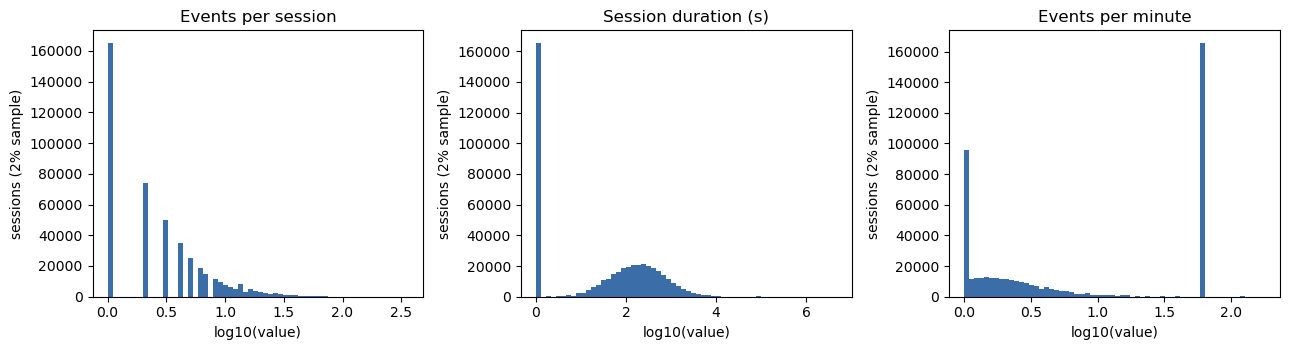

In [4]:
import matplotlib.pyplot as plt, numpy as np
samp = sf.sample(False, 0.02, seed=42).select("n_events","duration_sec","events_per_min","n_products").toPandas()
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for a, (col, title) in zip(ax, [("n_events","Events per session"),("duration_sec","Session duration (s)"),("events_per_min","Events per minute")]):
    a.hist(np.log10(samp[col].clip(lower=1)), bins=60, color="#3b6ea8")
    a.set_title(title); a.set_xlabel("log10(value)"); a.set_ylabel("sessions (2% sample)")
plt.tight_layout()
plt.savefig(f"{FIG}/fig_5_1_session_feature_distribution.png", dpi=160)
plt.show()

## 2. User–product interaction matrix for ALS
Implicit feedback: weight = 1·views + 3·carts + 5·purchases (confidence). The split is **temporal**: everything before `2019-11-24` is training, the last 7 days are test. Test keeps only purchase events from users and products already seen in training, so the model is judged on predicting future purchases.

In [5]:
CUTOFF = "2019-11-24"
W = {"view": 1.0, "cart": 3.0, "purchase": 5.0}
w = (F.when(F.col("event_type") == "view", W["view"])
      .when(F.col("event_type") == "cart", W["cart"]).otherwise(W["purchase"]))

def agg_pairs(df):
    return (df.groupBy("user_id", "product_id")
              .agg(F.sum(is_("view")).alias("n_view"), F.sum(is_("cart")).alias("n_cart"),
                   F.sum(is_("purchase")).alias("n_purchase"), F.sum(w).alias("weight"))
              .withColumn("user_id", F.col("user_id").cast("int"))
              .withColumn("product_id", F.col("product_id").cast("int")))

t0 = time.time()
train = agg_pairs(events.filter(F.col("event_date") < CUTOFF))
train.write.mode("overwrite").parquet(f"{GOLD}/als_train")

tr = spark.read.parquet(f"{GOLD}/als_train")
known_u = tr.select("user_id").distinct()
known_p = tr.select("product_id").distinct()
test = (agg_pairs(events.filter((F.col("event_date") >= CUTOFF) & (F.col("event_type") == "purchase")))
        .join(known_u, "user_id").join(known_p, "product_id"))
test.write.mode("overwrite").parquet(f"{GOLD}/als_test")
t_als = time.time() - t0

tr = spark.read.parquet(f"{GOLD}/als_train"); te = spark.read.parquet(f"{GOLD}/als_test")
n_tr, n_te = tr.count(), te.count()
stats = dict(
    train_pairs=n_tr, train_users=tr.select("user_id").distinct().count(),
    train_products=tr.select("product_id").distinct().count(),
    test_pairs=n_te, test_users=te.select("user_id").distinct().count())
stats["sparsity"] = 1 - n_tr / (stats["train_users"] * stats["train_products"])
print(stats, f"{t_als/60:.1f} min")

{'train_pairs': 50456607, 'train_users': 4875767, 'train_products': 198077, 'test_pairs': 113451, 'test_users': 79571, 'sparsity': 0.9999477554432094} 0.2 min


In [6]:
metrics = dict(sessions=n_sess, minutes_sessions=round(t_sess/60,2), minutes_als=round(t_als/60,2),
               cutoff=CUTOFF, weights=W, als=stats,
               session_summary=desc.reset_index().to_dict(orient="records"))
json.dump(metrics, open(f"{OUT}/02_metrics.json","w"), indent=2, default=str)
spark.stop()